In [2]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q diffusers==0.40.0 transformers==5.16.1 accelerate safetensors
import sys, platform, torch, diffusers, transformers, PIL
print("Python:", sys.version)
print("Platform:", platform.platform())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "GPU НЕ ДОСТУПЕН")
print("torch:", torch.__version__)
print("diffusers:", diffusers.__version__)
print("transformers:", transformers.__version__)
print("Pillow:", PIL.__version__)
assert torch.cuda.is_available()


name, memory.total [MiB]
Tesla T4, 15360 MiB
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
GPU: Tesla T4
torch: 2.11.0+cu130
diffusers: 0.40.0
transformers: 5.16.1
Pillow: 11.3.0


In [7]:
%%writefile lab05_lib.py
# ЛР 5. Запуск открытой модели text-to-image. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128, diffusers 0.40.0, transformers 5.16.1.
# Модель: stabilityai/sd-turbo, ревизия закреплена (см. REVISION). Веса загружаются с Hugging Face без авторизации.
import hashlib, io, time
import numpy as np
import torch
from PIL import Image
from diffusers import AutoPipelineForText2Image
from diffusers.utils import logging as dlog

dlog.set_verbosity_error()  # убирает предупреждения о приведении типов при pipe.to(dtype)

MODEL_ID = "stabilityai/sd-turbo"
REVISION = "b261bac6fd2cf515557d5d0707481eafa0485ec2"

# Пять контекстов (брифов). Во всех запретены текст, логотипы и люди.
BRIEFS = [
    "editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people",
    "square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people",
    "poster concept for a science exhibition, abstract constellation of connected nodes, dark background with white and cyan lines, balanced composition, no text, no logo",
    "visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people",
    "cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people",
]


def load_pipe(dtype=torch.float16):
    """Загружает закреплённую ревизию (файлы fp16) на GPU; dtype задаёт тип вычислений."""
    pipe = AutoPipelineForText2Image.from_pretrained(
        MODEL_ID, revision=REVISION, torch_dtype=torch.float16, variant="fp16", use_safetensors=True)
    pipe.set_progress_bar_config(disable=True)
    return pipe.to("cuda", dtype)


def generate(pipe, prompt, seed, steps=1, guidance=0.0, size=512, batch=1, gen_device="cpu"):
    """Возвращает список PIL-изображений. Для каждого элемента пакета свой генератор: seed, seed+1, ..."""
    gens = [torch.Generator(device=gen_device).manual_seed(seed + i) for i in range(batch)]
    return pipe(prompt=[prompt] * batch, num_inference_steps=steps, guidance_scale=guidance,
                height=size, width=size, generator=gens).images


def generate_fixed_noise(pipe, prompt, seed, steps=1, guidance=0.0, size=512):
    """Начальный шум всегда строится в float32 и приводится к типу вычислений: так меняется только точность."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    lat = torch.randn((1, 4, size // 8, size // 8), generator=g, dtype=torch.float32).to("cuda", pipe.unet.dtype)
    return pipe(prompt=[prompt], num_inference_steps=steps, guidance_scale=guidance, height=size, width=size, latents=lat).images[0]


def png_bytes(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return buf.getvalue()


def sha(data):
    return hashlib.sha256(data).hexdigest()


def to_arr(img):
    return np.asarray(img.convert("RGB"), dtype=np.float64)


def psnr_db(a, b):
    """PSNR для значений 0..255; inf, если изображения совпадают."""
    mse = np.mean((to_arr(a) - to_arr(b)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)


def max_abs_diff(a, b):
    return int(np.max(np.abs(to_arr(a) - to_arr(b))))


def jpeg_roundtrip(img, quality=90):
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf).convert("RGB"), buf.getvalue()


def classify(psnr, tol_db=40.0):
    """Классификация пары по допуску, заданному до эксперимента."""
    return "identical" if psnr == float("inf") else ("close" if psnr >= tol_db else "different")


# Шесть условий сравнения (фактор варианта). Каждое условие даёт пару изображений A и B.
CONDITIONS = ["repeat", "seed_plus_1", "generator_device", "dtype", "file_format", "batch"]


def make_pair(pipe, prompt, seed, cond):
    if cond == "repeat":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed)[0]
    elif cond == "seed_plus_1":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed + 1)[0]
    elif cond == "generator_device":
        a = generate(pipe, prompt, seed, gen_device="cpu")[0]; b = generate(pipe, prompt, seed, gen_device="cuda")[0]
    elif cond == "dtype":
        pipe.to(torch.float16); a = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float32); b = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float16)
    elif cond == "file_format":
        a = generate(pipe, prompt, seed)[0]; b, _ = jpeg_roundtrip(a, 90)
    elif cond == "batch":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed, batch=4)[0]
    else:
        raise ValueError(cond)
    return a, b


def variant_summary(pipe, n):
    """Вариант n = 1..30: контекст c = (n-1)//6 + 1, условие k = (n-1)%6 + 1."""
    c, k = (n - 1) // 6, (n - 1) % 6
    seed = 1000 + n
    t0 = time.perf_counter()
    a, b = make_pair(pipe, BRIEFS[c], seed, CONDITIONS[k])
    dt = time.perf_counter() - t0
    p = psnr_db(a, b)
    pf = None
    if CONDITIONS[k] == "dtype":  # проверка причины: одинаковый начальный шум в обоих режимах
        pipe.to(torch.float16); fa = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float32); fb = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float16); pf = psnr_db(fa, fb)
    return dict(variant=n, ctx=c + 1, cond=CONDITIONS[k], seed=seed, sha_a=sha(png_bytes(a)), sha_b=sha(png_bytes(b)),
                pixel_equal=bool(np.array_equal(to_arr(a), to_arr(b))), max_diff=max_abs_diff(a, b), psnr=p,
                verdict=classify(p), seconds=round(dt, 2), psnr_fixed_noise=pf)


Overwriting lab05_lib.py


In [4]:
import torch
import lab05_lib as L

pipe = L.load_pipe()

warmup_generator = torch.Generator(device="cpu").manual_seed(1011)

warmup_result = pipe(
    prompt="A simple abstract geometric composition",
    width=512,
    height=512,
    num_inference_steps=1,
    guidance_scale=0.0,
    generator=warmup_generator
)

print("Модель успешно загружена и прогрета.")

[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Модель успешно загружена и прогрета.


In [9]:
import json
from pathlib import Path
import lab05_lib as L

# Параметры варианта 11
prompt = L.BRIEFS[1]
seed = 1011

# Базовая генерация
images = L.generate(
    pipe=pipe,
    prompt=prompt,
    seed=seed,
    steps=1,
    guidance=0.0,
    size=512
)

image = images[0]

# Создание папки для результатов
output_dir = Path("artifacts/variant_11")
output_dir.mkdir(parents=True, exist_ok=True)

# Сохранение изображения
result_path = output_dir / "result.png"
image.save(result_path, format="PNG")

# Подготовка данных манифеста
manifest = {
    "variant": 11,
    "model": L.MODEL_ID,
    "revision": L.REVISION,
    "prompt": prompt,
    "seed": seed,
    "width": 512,
    "height": 512,
    "num_inference_steps": 1,
    "guidance_scale": 0.0,
    "format": "PNG",
    "filename": "result.png",
    "file_size_bytes": result_path.stat().st_size,
    "sha256": L.sha(result_path.read_bytes())
}

# Сохранение manifest.json
manifest_path = output_dir / "manifest.json"

with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, ensure_ascii=False, indent=4)

print("Базовый запуск выполнен.")
print("Изображение:", result_path)
print("Манифест:", manifest_path)
print("SHA-256:", manifest["sha256"])

Базовый запуск выполнен.
Изображение: artifacts/variant_11/result.png
Манифест: artifacts/variant_11/manifest.json
SHA-256: 3d6b41d9d72f63ccb9d1914fa5622f5bc7d363f3c6241aaab5a1e48333764646


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Загрузка, с: 1.61
Генерация, с: 0.29
SHA-256 PNG: 3d6b41d9d72f63ccb9d1914fa5622f5bc7d363f3c6241aaab5a1e48333764646
SHA-256 JPEG: 5c86a77c22999328506d163a604e8698f9013538d4bbe34fb1e4404c73e62789
Размер PNG, байт: 442080
Размер JPEG, байт: 99505
Совпадение пикселей: False
Максимальное отличие: 98
PSNR, дБ: 28.078079667847543
Вердикт по допуску 40 дБ: different


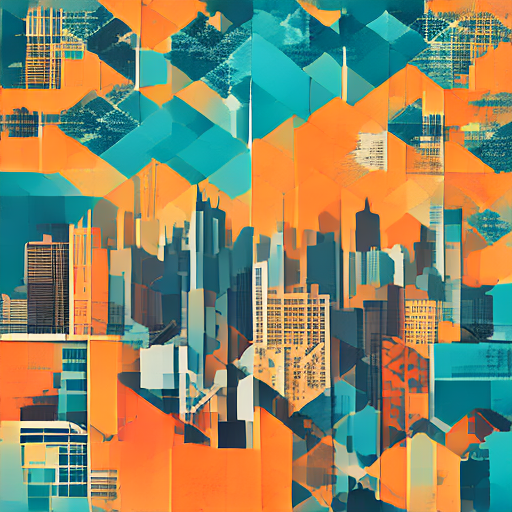

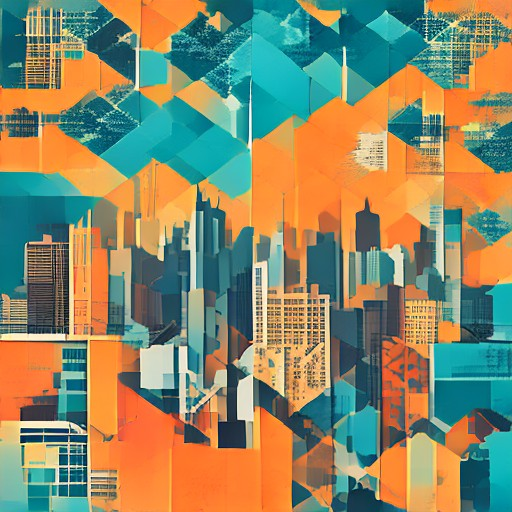

In [10]:
import json, pathlib, platform, sys, time, hashlib
import torch, diffusers, transformers, PIL
import numpy as np
from PIL import Image
import lab05_lib as L

N = 11
PROMPT = L.BRIEFS[1]       # бриф 2: городская среда
SEED = 1000 + N            # 1011
STEPS, GUIDANCE, SIZE = 1, 0.0, 512
OUT = pathlib.Path("artifacts/variant_11")
OUT.mkdir(parents=True, exist_ok=True)

# Загрузка и прогрев
t0 = time.perf_counter()
pipe = L.load_pipe()
load_seconds = round(time.perf_counter() - t0, 2)
_ = L.generate(pipe, PROMPT, SEED, STEPS, GUIDANCE, SIZE)  # прогрев

# Один исходный результат — затем два формата файла
t0 = time.perf_counter()
img = L.generate(pipe, PROMPT, SEED, STEPS, GUIDANCE, SIZE)[0].convert("RGB")
generation_seconds = round(time.perf_counter() - t0, 2)

png_data = L.png_bytes(img)
jpeg_img, jpeg_data = L.jpeg_roundtrip(img, quality=90)
png_path = OUT / "result_A.png"
jpg_path = OUT / "result_B.jpg"
roundtrip_path = OUT / "result_B_decoded.png"
png_path.write_bytes(png_data)
jpg_path.write_bytes(jpeg_data)
roundtrip_path.write_bytes(L.png_bytes(jpeg_img))

sha_png = L.sha(png_data)
sha_jpeg = L.sha(jpeg_data)
psnr = L.psnr_db(img, jpeg_img)
max_diff = L.max_abs_diff(img, jpeg_img)
pixel_equal = bool(np.array_equal(L.to_arr(img), L.to_arr(jpeg_img)))
verdict = L.classify(psnr, tol_db=40.0)

common = dict(
    model_id=L.MODEL_ID, revision=L.REVISION, prompt=PROMPT,
    seed=SEED, steps=STEPS, guidance_scale=GUIDANCE, size=SIZE,
    generator_device="cpu", dtype="float16",
    device=torch.cuda.get_device_name(0), platform=platform.platform(),
    python=sys.version.split()[0],
    packages={"torch": torch.__version__, "diffusers": diffusers.__version__,
              "transformers": transformers.__version__, "pillow": PIL.__version__},
    load_seconds=load_seconds, generation_seconds=generation_seconds,
    image_size=list(img.size), image_mode=img.mode
)
manifest_A = dict(common, file="result_A.png", format="PNG",
                  file_size_bytes=len(png_data), sha256=sha_png)
manifest_B = dict(common, file="result_B.jpg", format="JPEG", quality=90,
                  file_size_bytes=len(jpeg_data), sha256=sha_jpeg,
                  comparison_pixels="JPEG decoded to RGB")
(OUT / "manifest_A.json").write_text(json.dumps(manifest_A, ensure_ascii=False, indent=2), encoding="utf-8")
(OUT / "manifest_B.json").write_text(json.dumps(manifest_B, ensure_ascii=False, indent=2), encoding="utf-8")
(OUT / "comparison.json").write_text(json.dumps({
    "variant": 11, "seed": SEED,
    "sha256_A_png": sha_png, "sha256_B_jpeg": sha_jpeg,
    "size_A_bytes": len(png_data), "size_B_bytes": len(jpeg_data),
    "pixel_equal": pixel_equal, "max_abs_diff": max_diff,
    "psnr_db": psnr, "tolerance_db": 40.0, "verdict": verdict
}, ensure_ascii=False, indent=2), encoding="utf-8")

print("Загрузка, с:", load_seconds)
print("Генерация, с:", generation_seconds)
print("SHA-256 PNG:", sha_png)
print("SHA-256 JPEG:", sha_jpeg)
print("Размер PNG, байт:", len(png_data))
print("Размер JPEG, байт:", len(jpeg_data))
print("Совпадение пикселей:", pixel_equal)
print("Максимальное отличие:", max_diff)
print("PSNR, дБ:", psnr)
print("Вердикт по допуску 40 дБ:", verdict)
display(img)
display(jpeg_img)


In [11]:
# Намеренная ошибка: один и тот же генератор передан в два запуска
g = torch.Generator(device="cpu").manual_seed(SEED)
e1 = pipe(prompt=[PROMPT], num_inference_steps=STEPS, guidance_scale=GUIDANCE,
          height=SIZE, width=SIZE, generator=g).images[0].convert("RGB")
e2 = pipe(prompt=[PROMPT], num_inference_steps=STEPS, guidance_scale=GUIDANCE,
          height=SIZE, width=SIZE, generator=g).images[0].convert("RGB")
print("Первый запуск совпал с эталоном:", L.sha(L.png_bytes(e1)) == sha_png)
print("Второй запуск совпал с эталоном:", L.sha(L.png_bytes(e2)) == sha_png)
print("SHA-256 первого:", L.sha(L.png_bytes(e1)))
print("SHA-256 второго:", L.sha(L.png_bytes(e2)))
print("PSNR между двумя ошибочными запусками, дБ:", round(L.psnr_db(e1, e2), 2))


Первый запуск совпал с эталоном: True
Второй запуск совпал с эталоном: False
SHA-256 первого: 3d6b41d9d72f63ccb9d1914fa5622f5bc7d363f3c6241aaab5a1e48333764646
SHA-256 второго: a3dccb5b6abd1a6094a12065a64e01c079c28ba5c5cfb7fd98aeebdc073bea49
PSNR между двумя ошибочными запусками, дБ: 8.35


In [12]:
print(json.dumps({
    "variant": N, "brief": PROMPT, "factor": "PNG vs JPEG quality 90",
    "seed": SEED, "model": L.MODEL_ID, "revision": L.REVISION,
    "steps": STEPS, "guidance_scale": GUIDANCE, "size": SIZE,
    "generator_device": "cpu", "dtype": "float16",
    "gpu": torch.cuda.get_device_name(0),
    "files": sorted(p.name for p in OUT.iterdir())
}, ensure_ascii=False, indent=2))


{
  "variant": 11,
  "brief": "square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people",
  "factor": "PNG vs JPEG quality 90",
  "seed": 1011,
  "model": "stabilityai/sd-turbo",
  "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",
  "steps": 1,
  "guidance_scale": 0.0,
  "size": 512,
  "generator_device": "cpu",
  "dtype": "float16",
  "gpu": "Tesla T4",
  "files": [
    "comparison.json",
    "manifest.json",
    "manifest_A.json",
    "manifest_B.json",
    "result.png",
    "result_A.png",
    "result_B.jpg",
    "result_B_decoded.png"
  ]
}
